# Лабораторна №1, варіант 23

## Блок 1. Генерація даних

### 1.1. Імпорти, seed, папки

In [ ]:
import re, random, unicodedata
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
rng = np.random.default_rng(SEED)

RAW_DIR = Path("../data/raw");   RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR = Path("../data/clean"); CLEAN_DIR.mkdir(parents=True, exist_ok=True)

TZ = "Europe/Kyiv"
C_LAT, C_LON = 49.8397, 24.0297

### 1.2. Довідники: зупинки та маршрути

In [2]:
STREETS = ["Franka","Shevchenka","Lesi Ukrainky","Stryiska","Horodotska","Zelena",
           "Naukova","Chornovola","Kulparkivska","Pasichna","Lychakivska","Vulecka",
           "Knyazya Romana","Velykoho","Sykhivska","Kopernyka","Bandery","Rynok",
           "Opery","Vokzalna"]
KINDS = ["Square","Station","Park","Market"]
names = [f"{s} {k}" for s in STREETS for k in KINDS]

stops = pd.DataFrame({"stop_id": [f"S{i:03d}" for i in range(len(names))],
                      "stop_name": names})
stops["lat"] = C_LAT + rng.normal(0, 0.02, len(stops))
stops["lon"] = C_LON + rng.normal(0, 0.03, len(stops))
stop_info = stops.set_index("stop_id")

N_ROUTES = 12
route_stops = {f"R{r:02d}": rng.choice(stops["stop_id"].to_numpy(),
                                       size=int(rng.integers(45, 61)), replace=False)
               for r in range(1, N_ROUTES + 1)}

### 1.3. «Чисті» події

In [3]:
PEAK_HOURS = {7, 8, 16, 17, 18}
rows, ev = [], 0
for day in pd.date_range("2024-04-01", "2024-04-07"):
    for k in range(int(rng.integers(120, 181))):
        route_id = f"R{int(rng.integers(1, N_ROUTES + 1)):02d}"
        bus_id   = f"B{int(rng.integers(1, 41)):03d}"
        trip_id  = f"{day:%Y%m%d}-{route_id}-{k:03d}"
        start    = day + pd.Timedelta(minutes=int(rng.integers(330, 1320)))
        for i, sid in enumerate(route_stops[route_id]):
            sa = start + pd.Timedelta(minutes=2 * i)
            sd = sa + pd.Timedelta(seconds=30)
            peak = sa.hour in PEAK_HOURS
            delay = np.clip(rng.normal(10, 12), -5, 45) if peak else np.clip(rng.normal(2, 3.5), -5, 15)
            aa = sa + pd.Timedelta(seconds=float(delay) * 60)
            ad = aa + pd.Timedelta(seconds=int(rng.integers(15, 60)))
            b = int(rng.poisson(9 if peak else 4)); a = int(rng.poisson(9 if peak else 4))
            ev += 1
            rows.append(dict(event_id=f"E{ev:06d}", bus_id=bus_id, route_id=route_id,
                             trip_id=trip_id, stop_id=sid,
                             stop_name=stop_info.at[sid, "stop_name"],
                             lat=stop_info.at[sid, "lat"], lon=stop_info.at[sid, "lon"],
                             scheduled_arrival=sa, scheduled_departure=sd,
                             actual_arrival=aa, actual_departure=ad,
                             door_open=int(a + b > 0), boarding_est=b, alighting_est=a,
                             source_tz="Europe/Kyiv", note=None))
df = pd.DataFrame(rows)
print(df.shape)

(59985, 17)


### 1.4. «Брудимо» дані

#### Допоміжна функція. Вона бере точну частку рядків, а не «приблизну».

In [4]:
TIME_COLS = ["scheduled_arrival","scheduled_departure","actual_arrival","actual_departure"]
def sample_idx(frac):
    return rng.choice(df.index.to_numpy(), size=int(len(df) * frac), replace=False)

#### a. Нелогічні затримки (1 %)

In [5]:
bad = sample_idx(0.01)
shift = np.where(rng.random(len(bad)) < 0.5, rng.uniform(-60, -16, len(bad)), rng.uniform(61, 120, len(bad)))
df.loc[bad, "actual_arrival"] = df.loc[bad, "scheduled_arrival"] + pd.to_timedelta(shift, unit="min")
df.loc[bad, "actual_departure"] = df.loc[bad, "actual_arrival"] + pd.Timedelta(seconds=30)

#### b. Гео-аномалії: віддалені точки (1 %) і переплутані lat/lon (1,75 %)

In [6]:
far = sample_idx(0.01)
df.loc[far, "lat"] += rng.choice([-1, 1], len(far)) * rng.uniform(0.22, 0.40, len(far))
rest = df.index.difference(far)
swap = rng.choice(rest.to_numpy(), size=int(len(df) * 0.0175), replace=False)
df.loc[swap, ["lat", "lon"]] = df.loc[swap, ["lon", "lat"]].to_numpy()

#### c. Логічно неможливі пасажири + число як текст

In [7]:
for c in ["boarding_est", "alighting_est"]:
    neg = sample_idx(0.005); df.loc[neg, c] = -rng.integers(1, 6, len(neg))
    big = sample_idx(0.005); df.loc[big, c] = rng.integers(80, 200, len(big))

df["boarding_est"] = df["boarding_est"].astype(object)
txt = sample_idx(0.06)
df.loc[txt, "boarding_est"] = df.loc[txt, "boarding_est"].map(lambda v: f"\u00a0{v},0 ")

#### d. Назви зупинок: синоніми, опечатки, регістр, пробіли

In [8]:
SYN = {"Square":["Sq.","Sq"], "Station":["Stn","Stat."], "Park":["Pk."], "Market":["Mkt"]}
def typo(s):
    i = int(rng.integers(1, len(s) - 1))
    return s[:i] + s[i+1:] if rng.random() < 0.5 else s[:i] + s[i+1] + s[i] + s[i+2:]
def noisy_name(s):
    r = rng.random()
    if r < 0.12: w = s.split(); w[-1] = random.choice(SYN[w[-1]]); return " ".join(w)
    if r < 0.17: return typo(s)
    if r < 0.25: return s.upper()
    if r < 0.30: return s.lower()
    if r < 0.38: return "  " + s + " "
    return s
df["stop_name"] = df["stop_name"].map(noisy_name)

#### e. Поле note з невидимими символами

In [9]:
NOTES = ["detour","crowded","door fault","driver change","road works","ok"]
df["note"] = np.where(rng.random(len(df)) < 0.3, rng.choice(NOTES, len(df)), None)
inv = df["note"].notna() & (rng.random(len(df)) < 0.4)
df.loc[inv, "note"] = df.loc[inv, "note"].map(lambda s: "\u200b" + s.replace(" ", "\u00a0") + "\ufeff")

#### f. Часові пояси та формати дат

In [10]:
trips = df["trip_id"].unique()
tz_map = dict(zip(trips, np.where(rng.random(len(trips)) < 0.3, "UTC", "Europe/Kyiv")))
df["source_tz"] = df["trip_id"].map(tz_map)
is_utc = df["source_tz"].eq("UTC")

for c in TIME_COLS:
    t = df[c].copy()
    t = t.where(~is_utc, t - pd.Timedelta(hours=3))
    s = t.dt.strftime("%Y-%m-%dT%H:%M:%S")
    dot = sample_idx(0.12)
    s.loc[dot] = t.loc[dot].dt.strftime("%d.%m.%Y %H:%M:%S")
    df[c] = s

#### g. Пропуски (+ груповий блок)

In [11]:
def set_nan(cols, frac):
    df.loc[sample_idx(frac), cols] = np.nan
set_nan(["actual_arrival"], 0.085)
set_nan(["actual_departure"], 0.11)
block = df["route_id"].eq("R05") & df["trip_id"].str.startswith("20240404")
df.loc[block, "actual_departure"] = np.nan
set_nan(["lat", "lon"], 0.05)
set_nan(["boarding_est"], 0.10); set_nan(["alighting_est"], 0.10)

#### h. Дублі: 1,75 %, половина повні, половина «майже»

In [12]:
k = int(len(df) * 0.0175)
src = rng.choice(df.index.to_numpy(), size=k, replace=False)
dups = df.loc[src].copy()
near = dups.index[k // 2:]
variants = [str.upper, str.lower, lambda x: "  " + x + "  "]
dups.loc[near, "stop_name"] = dups.loc[near, "stop_name"].map(lambda s: random.choice(variants)(s))
dups.loc[near, "event_id"] = [f"E{200000+i}" for i in range(len(near))]
lose = near[: len(near) // 3]
dups.loc[lose, ["actual_arrival", "actual_departure"]] = np.nan
df = pd.concat([df, dups]).sample(frac=1, random_state=SEED).reset_index(drop=True)

### 1.5. Самоперевірка і збереження

In [13]:
COLUMNS = ["event_id","bus_id","route_id","trip_id","stop_id","stop_name","lat","lon",
           "scheduled_arrival","scheduled_departure","actual_arrival","actual_departure",
           "door_open","boarding_est","alighting_est","source_tz","note"]
df = df[COLUMNS]
print(df.shape)
print(df.isna().mean().mul(100).round(1))
print("dup key:", df.duplicated(["trip_id","stop_id","scheduled_arrival"]).mean()*100)
print("не-ISO %:", df["scheduled_arrival"].str.match(r"^\d{2}\.").mean()*100)
print(df["source_tz"].value_counts(normalize=True))

df.to_csv(RAW_DIR / "generated_dirty.csv", index=False, encoding="utf-8")
df.to_csv(RAW_DIR / "stop_events_flat.csv", index=False, encoding="utf-8")

(61034, 17)
event_id                0.0
bus_id                  0.0
route_id                0.0
trip_id                 0.0
stop_id                 0.0
stop_name               0.0
lat                     5.0
lon                     5.0
scheduled_arrival       0.0
scheduled_departure     0.0
actual_arrival          8.8
actual_departure       12.7
door_open               0.0
boarding_est           10.0
alighting_est          10.0
source_tz               0.0
note                   70.1
dtype: float64
dup key: 1.7187141593210342
не-ISO %: 12.004784218632238
source_tz
Europe/Kyiv    0.701494
UTC            0.298506
Name: proportion, dtype: float64


## Блок 2. Описова статистика «до»

### 2.1. Завантаження і допоміжні функції

In [14]:
raw = pd.read_csv(RAW_DIR / "generated_dirty.csv")
KEY = ["trip_id", "stop_id", "scheduled_arrival"]
ISO_RE = r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}$"
DOT_RE = r"^\d{2}\.\d{2}\.\d{4} \d{2}:\d{2}:\d{2}$"

def parse_mixed(s):
    """Парсить два формати за явними масками, без вгадування pandas."""
    s = s.astype("string").str.strip()
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    m_iso = s.str.match(ISO_RE).fillna(False).astype(bool)
    m_dot = s.str.match(DOT_RE).fillna(False).astype(bool)
    out[m_iso] = pd.to_datetime(s[m_iso], format="%Y-%m-%dT%H:%M:%S")
    out[m_dot] = pd.to_datetime(s[m_dot], format="%d.%m.%Y %H:%M:%S")
    return out

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

def to_num(s):
    s = s.astype("string").str.replace(r"[\s\u00a0\u200b]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(s, errors="coerce")

### 2.2. Діагностика за пунктами варіанту

#### a. Розмір і унікальні значення

In [15]:
print(raw.shape); display(raw.dtypes)
display(raw[["bus_id","route_id","trip_id","stop_id"]].nunique())

(61034, 17)


event_id                   str
bus_id                     str
route_id                   str
trip_id                    str
stop_id                    str
stop_name                  str
lat                    float64
lon                    float64
scheduled_arrival          str
scheduled_departure        str
actual_arrival             str
actual_departure           str
door_open                int64
boarding_est               str
alighting_est          float64
source_tz                  str
note                       str
dtype: object

bus_id        40
route_id      12
trip_id     1125
stop_id       80
dtype: int64

#### b. Пропуски

In [16]:
display(raw.isna().mean().mul(100).round(2).sort_values(ascending=False))

note                   70.07
actual_departure       12.75
alighting_est           9.98
boarding_est            9.97
actual_arrival          8.78
lat                     4.99
lon                     4.99
event_id                0.00
bus_id                  0.00
scheduled_arrival       0.00
stop_name               0.00
trip_id                 0.00
stop_id                 0.00
route_id                0.00
scheduled_departure     0.00
door_open               0.00
source_tz               0.00
dtype: float64

#### c. Дублі

In [17]:
full = raw.duplicated().sum()
by_key = raw.duplicated(KEY).sum()
print("повних:", full, "| «майже»:", by_key - full)

повних: 524 | «майже»: 525


#### d. Не-ISO дати та TZ

In [18]:
for c in ["scheduled_arrival", "actual_arrival"]:
    print(c, "не-ISO %:", round(raw[c].dropna().str.match(DOT_RE).mean() * 100, 2))
display(raw["source_tz"].value_counts(normalize=True))

scheduled_arrival не-ISO %: 12.0
actual_arrival не-ISO %: 11.95


source_tz
Europe/Kyiv    0.701494
UTC            0.298506
Name: proportion, dtype: float64

#### e. Гео

In [19]:
swapped = raw["lat"].abs() < raw["lon"].abs()
lat_f = raw["lat"].where(~swapped, raw["lon"]); lon_f = raw["lon"].where(~swapped, raw["lat"])
far = haversine(lat_f, lon_f, C_LAT, C_LON) > 20
print("переплутані %:", swapped.mean() * 100, "| далекі %:", far.mean() * 100)
display(raw[far].head())

переплутані %: 1.684307107513845 | далекі %: 0.9519284333322411


,event_id,bus_id,route_id,trip_id,stop_id,stop_name,lat,lon,scheduled_arrival,scheduled_departure,actual_arrival,actual_departure,door_open,boarding_est,alighting_est,source_tz,note
26,E058835,B013,R07,20240407-R07-147,S021,Zelena Station,49.473539,24.068677,2024-04-07T08:06:00,2024-04-07T08:06:30,2024-04-07T08:11:31,2024-04-07T08:12:11,1,4,3.0,UTC,detour
221,E006341,B036,R12,20240401-R12-119,S040,LYCHAKIVSKA SQUARE,50.212966,23.998995,2024-04-01T22:36:00,2024-04-01T22:36:30,2024-04-01T22:38:01,2024-04-01T22:38:57,1,1,3.0,Europe/Kyiv,NaN
599,E023680,B017,R03,20240403-R03-165,S018,Horootska Park,50.201683,24.041693,03.04.2024 15:50:00,2024-04-03T15:50:30,2024-04-03T16:13:52,2024-04-03T16:14:25,1,196,10.0,UTC,​detour﻿
727,E000445,B002,R09,20240401-R09-008,S013,Stryiska Stat.,50.086572,24.027308,2024-04-01T15:01:00,2024-04-01T15:01:30,2024-04-01T15:07:48,NaN,1,0,7.0,Europe/Kyiv,NaN
792,E032968,B011,R10,20240405-R10-009,S046,Vulecka Park,50.239884,24.073599,2024-04-05T19:48:00,2024-04-05T19:48:30,2024-04-05T19:47:16,2024-04-05T19:47:57,1,2,4.0,Europe/Kyiv,NaN


#### f. Затримки

count    55676.000000
mean         4.881953
std         10.477298
min        -59.933333
25%         -0.166667
50%          2.850000
75%          6.666667
max        119.933333
dtype: float64

count    53254.000000
mean         5.024749
std         10.419333
min        -59.933333
25%         -0.033333
50%          2.983333
75%          6.816667
max        119.933333
dtype: float64

нелогічних %: 1.01479991378691


<Axes: >

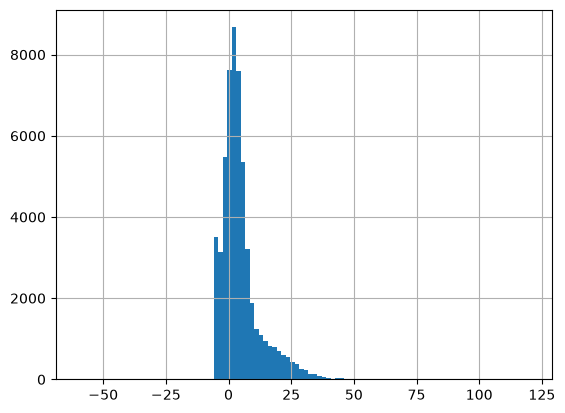

In [20]:
d_arr = (parse_mixed(raw["actual_arrival"]) - parse_mixed(raw["scheduled_arrival"])).dt.total_seconds() / 60
d_dep = (parse_mixed(raw["actual_departure"]) - parse_mixed(raw["scheduled_departure"])).dt.total_seconds() / 60
display(d_arr.describe()); display(d_dep.describe())
illog = ((d_arr < -15) | (d_arr > 60)).sum() / d_arr.notna().sum()
print("нелогічних %:", illog * 100)
d_arr.clip(-80, 130).hist(bins=100)

## Блок 3. Очистка

### 3.1. План правил

In [21]:
pd.set_option("display.max_colwidth", None)

plan = pd.DataFrame([
 # 1. Повні дублі
 ["всі поля", "повні дублі (ідентичні рядки, включно з event_id)",
  "drop_duplicates() по всіх колонках, до будь-якої нормалізації",
  "−≈0.9% рядків (половина від 1.75% дублів)",
  "робимо першим, щоб не обробляти зайве; кількість пишемо в change_log"],

 # 2. Час і TZ
 ["scheduled_arrival/departure, actual_arrival/departure",
  "змішані формати (ISO і DD.MM.YYYY HH:MM:SS) та змішані TZ (UTC / Europe/Kyiv)",
  "парсинг за явними масками (regex + format) → для source_tz=UTC: localize('UTC') → convert('Europe/Kyiv'); для Kyiv: localize('Europe/Kyiv')",
  "100% часових значень у одному форматі й поясі; UTC-рядки зсуваються на +3 год (квітень = літній час)",
  "NaT залишаються NaT; source_tz після обробки = Europe/Kyiv; оригінал зберігаємо в source_tz_orig для KPI 'UTC до/після'"],

 # 3. Імена зупинок
 ["stop_name",
  "синоніми (Sq., Stn, Pk., Mkt), опечатки, змішаний регістр, зайві пробіли",
  "trim + стиснення пробілів + lower → словник синонімів → title(); далі канонічна назва = мода по stop_id",
  "одна назва на кожен stop_id (≈80 унікальних замість сотень варіантів)",
  "мода по stop_id виправляє опечатки без ручного словника; прапорець name_changed"],

 # 4. Майже дублі
 ["trip_id + stop_id + scheduled_arrival",
  "«майже» дублі (різниця лише в регістрі/пробілах stop_name, інший event_id)",
  "сортування за кількістю непорожніх actual_* (спадання) → drop_duplicates(KEY, keep='first')",
  "−≈0.9% рядків; ключ стає унікальним",
  "виконуємо ПІСЛЯ нормалізації часу й імен, інакше ключ не збігається; лишаємо запис з найповнішими actual_*"],

 # 5. Гео: переплутані lat/lon
 ["lat, lon",
  "переплутані місцями (≈1.75%)",
  "якщо |lat| < |lon| → міняємо місцями (для України lat ≈ 44–52, lon ≈ 22–40)",
  "0 переплутаних координат",
  "перед обміном обов'язково .to_numpy(); прапорець geo_fixed → KPI 'частка виправлених lat/lon'"],

 # 6. Гео: далекі точки і пропуски
 ["lat, lon",
  "точки >20 км від центру (≈1%) та пропуски (≈5%)",
  "haversine до центру > 20 км → NaN; далі заповнюємо медіаною координат того ж stop_id",
  "усі координати в межах міста, пропусків lat/lon ≈ 0%",
  "зупинка нерухома, тому медіана по stop_id точна; рядок не видаляємо, бо подія (затримка, пасажири) цінна; прапорці geo_far, geo_imputed"],

 # 7. Пасажиропотік
 ["boarding_est, alighting_est",
  "числа як текст ('\\u00a012,0 '), від'ємні значення, завеликі (>60), пропуски",
  "прибрати пробіли/nbsp/zero-width → кому в крапку → to_numeric; від'ємні → NA; значення >60 → кліп до 60",
  "тип float, усі значення в [0, 60] або NA",
  "пропуски (≈10%) НЕ імпутуємо, щоб не вигадувати пасажирів; прапорець pass_changed"],

 # 8. note
 ["note",
  "невидимі символи (zero-width space, BOM, nbsp)",
  "nbsp → пробіл; видалення символів Unicode-категорій Cf і Cc; strip()",
  "текст без прихованих символів, порівняння рядків працює коректно",
  "прапорець note_changed; порожні note лишаються NA"],

 # 9. Затримки
 ["delay_arrival, delay_departure, invalid_timing, is_peak",
  "нелогічні затримки (<−15 хв або >+60 хв, ≈1%)",
  "delay = actual − scheduled у хвилинах; invalid_timing=1, якщо поза [−15, +60] хв; is_peak за годиною (7–8, 16–18)",
  "нові колонки; нелогічні рядки позначені, але НЕ видалені",
  "рахуємо після нормалізації TZ; у KPI беремо лише invalid_timing=0; пропуск actual_* → delay = NaN"],

 # 10. door_open
 ["door_open",
  "окремого «бруду» не вносилось; можливі значення поза {0,1}",
  "лише валідація: isin([0, 1]); змін не вносимо",
  "0 змін; перевірка в блоці валідацій",
  "якщо знайдуться значення поза {0,1}, то → NA і запис у change_log"],

 # 11. Прапорці і лог
 ["row_changed",
  "потрібна прозорість: які рядки змінено",
  "row_changed = geo_fixed | geo_far | geo_imputed | name_changed | pass_changed | note_changed",
  "KPI '% рядків зі змінами'; повна простежуваність",
  "нормалізація часу в row_changed не входить (її зазнають усі рядки); усі кроки пишуться у change_log.csv"],
], columns=["поле", "проблема", "метод/правило", "очікуваний ефект", "примітки"])

display(plan)

,поле,проблема,метод/правило,очікуваний ефект,примітки
0,всі поля,"повні дублі (ідентичні рядки, включно з event_id)","drop_duplicates() по всіх колонках, до будь-якої нормалізації",−≈0.9% рядків (половина від 1.75% дублів),"робимо першим, щоб не обробляти зайве; кількість пишемо в change_log"
1,"scheduled_arrival/departure, actual_arrival/departure",змішані формати (ISO і DD.MM.YYYY HH:MM:SS) та змішані TZ (UTC / Europe/Kyiv),парсинг за явними масками (regex + format) → для source_tz=UTC: localize('UTC') → convert('Europe/Kyiv'); для Kyiv: localize('Europe/Kyiv'),100% часових значень у одному форматі й поясі; UTC-рядки зсуваються на +3 год (квітень = літній час),NaT залишаються NaT; source_tz після обробки = Europe/Kyiv; оригінал зберігаємо в source_tz_orig для KPI 'UTC до/після'
2,stop_name,"синоніми (Sq., Stn, Pk., Mkt), опечатки, змішаний регістр, зайві пробіли",trim + стиснення пробілів + lower → словник синонімів → title(); далі канонічна назва = мода по stop_id,одна назва на кожен stop_id (≈80 унікальних замість сотень варіантів),мода по stop_id виправляє опечатки без ручного словника; прапорець name_changed
3,trip_id + stop_id + scheduled_arrival,"«майже» дублі (різниця лише в регістрі/пробілах stop_name, інший event_id)","сортування за кількістю непорожніх actual_* (спадання) → drop_duplicates(KEY, keep='first')",−≈0.9% рядків; ключ стає унікальним,"виконуємо ПІСЛЯ нормалізації часу й імен, інакше ключ не збігається; лишаємо запис з найповнішими actual_*"
4,"lat, lon",переплутані місцями (≈1.75%),"якщо |lat| < |lon| → міняємо місцями (для України lat ≈ 44–52, lon ≈ 22–40)",0 переплутаних координат,перед обміном обов'язково .to_numpy(); прапорець geo_fixed → KPI 'частка виправлених lat/lon'
5,"lat, lon",точки >20 км від центру (≈1%) та пропуски (≈5%),haversine до центру > 20 км → NaN; далі заповнюємо медіаною координат того ж stop_id,"усі координати в межах міста, пропусків lat/lon ≈ 0%","зупинка нерухома, тому медіана по stop_id точна; рядок не видаляємо, бо подія (затримка, пасажири) цінна; прапорці geo_far, geo_imputed"
6,"boarding_est, alighting_est","числа як текст ('\u00a012,0 '), від'ємні значення, завеликі (>60), пропуски",прибрати пробіли/nbsp/zero-width → кому в крапку → to_numeric; від'ємні → NA; значення >60 → кліп до 60,"тип float, усі значення в [0, 60] або NA","пропуски (≈10%) НЕ імпутуємо, щоб не вигадувати пасажирів; прапорець pass_changed"
7,note,"невидимі символи (zero-width space, BOM, nbsp)",nbsp → пробіл; видалення символів Unicode-категорій Cf і Cc; strip(),"текст без прихованих символів, порівняння рядків працює коректно",прапорець note_changed; порожні note лишаються NA
8,"delay_arrival, delay_departure, invalid_timing, is_peak","нелогічні затримки (<−15 хв або >+60 хв, ≈1%)","delay = actual − scheduled у хвилинах; invalid_timing=1, якщо поза [−15, +60] хв; is_peak за годиною (7–8, 16–18)","нові колонки; нелогічні рядки позначені, але НЕ видалені",рахуємо після нормалізації TZ; у KPI беремо лише invalid_timing=0; пропуск actual_* → delay = NaN
9,door_open,"окремого «бруду» не вносилось; можливі значення поза {0,1}","лише валідація: isin([0, 1]); змін не вносимо",0 змін; перевірка в блоці валідацій,"якщо знайдуться значення поза {0,1}, то → NA і запис у change_log"


### 3.2. Реалізація: функції clean_*

In [22]:
log = []
def log_change(field, rule, n, example=""):
    log.append({"field": field, "rule": rule, "n_changed": int(n), "example": str(example)[:80]})

SYNONYMS = {"sq.":"square","sq":"square","stn":"station","stat.":"station","pk.":"park","mkt":"market"}
def norm_name(s):
    if pd.isna(s): return s
    w = re.sub(r"\s+", " ", str(s)).strip().lower().split(" ")
    return " ".join(SYNONYMS.get(x, x) for x in w).title()

def clean_full_duplicates(df):
    n = df.duplicated().sum()
    df = df.drop_duplicates().copy()
    log_change("*", "drop full duplicates", n)
    return df

def clean_times(df):
    df = df.copy()
    if "source_tz_orig" not in df: df["source_tz_orig"] = df["source_tz"].str.strip()
    is_utc = df["source_tz_orig"].eq("UTC")
    for c in TIME_COLS:
        if pd.api.types.is_datetime64_any_dtype(df[c]): continue
        n_dot = df[c].dropna().str.match(DOT_RE).sum()
        dt = parse_mixed(df[c])
        p_utc = dt[is_utc].dt.tz_localize("UTC").dt.tz_convert(TZ)
        p_loc = dt[~is_utc].dt.tz_localize(TZ)
        df[c] = pd.concat([p_utc, p_loc]).reindex(df.index)
        log_change(c, "parse DD.MM.YYYY/ISO; normalize to Kyiv", n_dot, df[c].dropna().iloc[0])
    df["source_tz"] = TZ
    return df

def clean_names(df):
    df = df.copy(); before = df["stop_name"].copy()
    df["stop_name"] = df["stop_name"].map(norm_name)

    df["stop_name"] = df.groupby("stop_id")["stop_name"].transform(lambda x: x.mode().iloc[0])
    df["name_changed"] = before != df["stop_name"]
    log_change("stop_name", "trim/synonyms/title + mode per stop_id", df["name_changed"].sum(),
               f"{before[df['name_changed']].iloc[0]!r} → {df.loc[df['name_changed'], 'stop_name'].iloc[0]!r}")
    return df

def clean_near_duplicates(df):
    df = df.copy()
    df["_n"] = df[["actual_arrival", "actual_departure"]].notna().sum(axis=1)
    n = df.duplicated(KEY).sum()
    df = (df.sort_values("_n", ascending=False, kind="stable")
            .drop_duplicates(KEY, keep="first").sort_index().drop(columns="_n"))
    log_change("*", "near-duplicates by trip+stop+scheduled_arrival, keep most complete", n)
    return df

def clean_geo(df):
    df = df.copy()
    swap = df["lat"].abs() < df["lon"].abs()
    df.loc[swap, ["lat", "lon"]] = df.loc[swap, ["lon", "lat"]].to_numpy()
    df["geo_fixed"] = swap
    far = haversine(df["lat"], df["lon"], C_LAT, C_LON) > 20
    df["geo_far"] = far
    df.loc[far, ["lat", "lon"]] = np.nan
    df["geo_imputed"] = df["lat"].isna()
    med = df.groupby("stop_id")[["lat", "lon"]].transform("median")
    df["lat"] = df["lat"].fillna(med["lat"]); df["lon"] = df["lon"].fillna(med["lon"])
    log_change("lat/lon", "swap if |lat|<|lon|", swap.sum())
    log_change("lat/lon", "far (>20km) → NaN → median by stop_id", df["geo_imputed"].sum())
    return df

def clean_passengers(df):
    df = df.copy(); changed = pd.Series(False, index=df.index)
    for c in ["boarding_est", "alighting_est"]:
        orig = df[c]
        is_txt = orig.astype("string").str.contains(r"[^\d\.\-]", na=False)
        v = to_num(orig)
        neg, big = v < 0, v > 60
        df[c] = v.mask(neg).clip(upper=60)
        changed |= (neg | big | is_txt).fillna(False)
        log_change(c, "text→number; neg→NA; clip [0,60]", (neg | big | is_txt).sum())
    df["pass_changed"] = changed
    return df

def clean_note(df):
    df = df.copy(); before = df["note"].copy()
    def f(s):
        if pd.isna(s): return s
        s = str(s).replace("\u00a0", " ")
        return "".join(ch for ch in s if unicodedata.category(ch) not in ("Cf", "Cc")).strip()
    df["note"] = df["note"].map(f)
    df["note_changed"] = before.fillna("") != df["note"].fillna("")
    log_change("note", "remove invisible chars", df["note_changed"].sum())
    return df

def clean_delays(df):
    df = df.copy()
    df["delay_arrival"]   = (df["actual_arrival"]   - df["scheduled_arrival"]).dt.total_seconds() / 60
    df["delay_departure"] = (df["actual_departure"] - df["scheduled_departure"]).dt.total_seconds() / 60
    bad_a = df["delay_arrival"].notna() & ~df["delay_arrival"].between(-15, 60)
    bad_d = df["delay_departure"].notna() & ~df["delay_departure"].between(-15, 60)
    df["invalid_timing"] = (bad_a | bad_d).astype(int)
    df["is_peak"] = df["scheduled_arrival"].dt.hour.isin([7, 8, 16, 17, 18]).astype(int)
    log_change("delay_*", "compute delays; invalid_timing outside [-15,60]", df["invalid_timing"].sum())
    return df

def clean_all(raw):
    log.clear()
    df = raw.copy()
    df = clean_full_duplicates(df); df = clean_times(df); df = clean_names(df)
    df = clean_near_duplicates(df); df = clean_geo(df); df = clean_passengers(df)
    df = clean_note(df); df = clean_delays(df)
    flags = ["geo_fixed", "geo_far", "geo_imputed", "name_changed", "pass_changed", "note_changed"]
    df["row_changed"] = df[flags].any(axis=1)
    return df.reset_index(drop=True)

clean = clean_all(raw)
pd.DataFrame(log).to_csv("../change_log.csv", index=False)
clean.to_csv(CLEAN_DIR / "dataset_clean.csv", index=False)
clean.to_parquet(CLEAN_DIR / "dataset_clean.parquet")
display(pd.DataFrame(log))

,field,rule,n_changed,example
0,*,drop full duplicates,524,
1,scheduled_arrival,parse DD.MM.YYYY/ISO; normalize to Kyiv,7258,2024-04-06 15:57:00+03:00
2,scheduled_departure,parse DD.MM.YYYY/ISO; normalize to Kyiv,7250,2024-04-06 15:57:30+03:00
3,actual_arrival,parse DD.MM.YYYY/ISO; normalize to Kyiv,6598,2024-04-06 15:58:59+03:00
4,actual_departure,parse DD.MM.YYYY/ISO; normalize to Kyiv,6339,2024-04-06 15:59:55+03:00
5,stop_name,trim/synonyms/title + mode per stop_id,23397,'Zelena Sq' → 'Zelena Square'
6,*,"near-duplicates by trip+stop+scheduled_arrival, keep most complete",525,
7,lat/lon,swap if |lat|<|lon|,1005,
8,lat/lon,far (>20km) → NaN → median by stop_id,3572,
9,boarding_est,"text→number; neg→NA; clip [0,60]",3736,


### 3.3. Валідації (потрібно ≥ 8)

In [23]:
MAX_INVALID = 0.02
checks = {
 "1 час у datetime": all(pd.api.types.is_datetime64_any_dtype(clean[c]) for c in TIME_COLS),
 "2 TZ = Kyiv": all(str(clean[c].dt.tz) in ("Europe/Kyiv", "Europe/Kiev") for c in TIME_COLS),
 "3 немає дублів за ключем": not clean.duplicated(KEY).any(),
 "4 немає повних дублів": not clean.drop(columns=[]).duplicated().any(),
 "5 координати валідні": clean["lat"].dropna().between(-90, 90).all() and clean["lon"].dropna().between(-180, 180).all(),
 "6 door_open ∈ {0,1}": clean["door_open"].isin([0, 1]).all(),
 "7 boarding/alighting ∈ [0,60] або NA": all(clean[c].dropna().between(0, 60).all() for c in ["boarding_est", "alighting_est"]),
 "8 немає переплутаних lat/lon": (clean["lat"].abs() >= clean["lon"].abs()).all(),
 "9 invalid_timing ≤ порогу": clean["invalid_timing"].mean() <= MAX_INVALID,
 "10 одна назва на stop_id": clean.groupby("stop_id")["stop_name"].nunique().max() == 1,
}
res = pd.Series(checks).map({True: "PASS", False: "FAIL"}); display(res)
assert (res == "PASS").all()

1 час у datetime                        PASS
2 TZ = Kyiv                             PASS
3 немає дублів за ключем                PASS
4 немає повних дублів                   PASS
5 координати валідні                    PASS
6 door_open ∈ {0,1}                     PASS
7 boarding/alighting ∈ [0,60] або NA    PASS
8 немає переплутаних lat/lon            PASS
9 invalid_timing ≤ порогу               PASS
10 одна назва на stop_id                PASS
dtype: str

## Блок 4. Статистика «після»

,до,після
рядків,61034.00,59985.00
% пропусків actual_arrival,8.78,8.50
% пропусків actual_departure,12.75,12.49
% пропусків lat/lon,4.99,0.00
% пропусків boarding,9.97,10.45
дублів за ключем,1049.00,0.00
переплутані lat/lon,1028.00,0.00
нелогічні затримки %,1.01,0.99


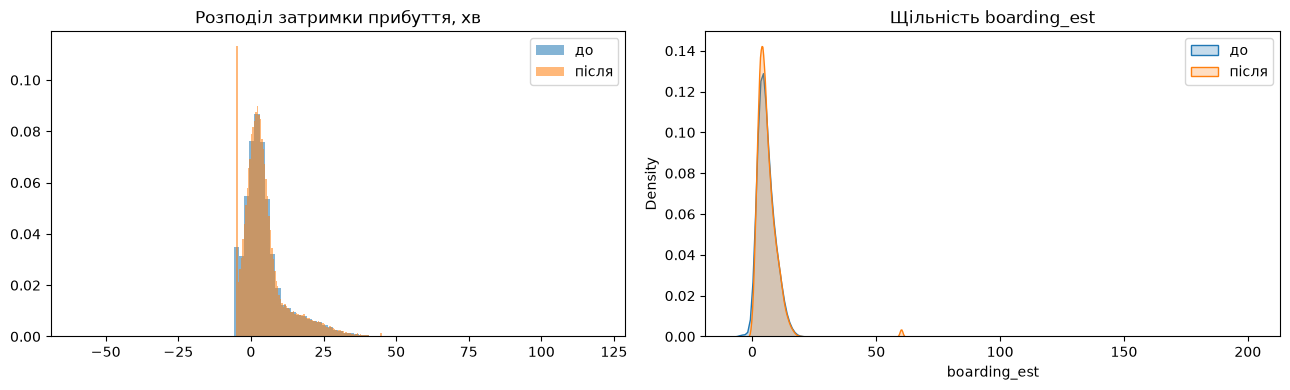

In [ ]:
before = {"рядків": len(raw),
          "% пропусків actual_arrival": raw["actual_arrival"].isna().mean()*100,
          "% пропусків actual_departure": raw["actual_departure"].isna().mean()*100,
          "% пропусків lat/lon": raw["lat"].isna().mean()*100,
          "% пропусків boarding": raw["boarding_est"].isna().mean()*100,
          "дублів за ключем": raw.duplicated(KEY).sum(),
          "переплутані lat/lon": (raw["lat"].abs() < raw["lon"].abs()).sum(),
          "нелогічні затримки %": illog*100}
after = {"рядків": len(clean),
         "% пропусків actual_arrival": clean["actual_arrival"].isna().mean()*100,
         "% пропусків actual_departure": clean["actual_departure"].isna().mean()*100,
         "% пропусків lat/lon": clean["lat"].isna().mean()*100,
         "% пропусків boarding": clean["boarding_est"].isna().mean()*100,
         "дублів за ключем": clean.duplicated(KEY).sum(),
         "переплутані lat/lon": (clean["lat"].abs() < clean["lon"].abs()).sum(),
         "нелогічні затримки %": clean["invalid_timing"].mean()*100}
display(pd.DataFrame({"до": before, "після": after}).round(2))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(d_arr.dropna().clip(-80, 130), bins=100, density=True, alpha=.55, label="до")
ax[0].hist(clean.loc[clean["invalid_timing"] == 0, "delay_arrival"].dropna(), bins=100, density=True, alpha=.55, label="після")
ax[0].set(title="Розподіл затримки прибуття, хв"); ax[0].legend()
sns.kdeplot(to_num(raw["boarding_est"]).dropna(), ax=ax[1], label="до", fill=True)
sns.kdeplot(clean["boarding_est"].dropna(), ax=ax[1], label="після", fill=True)
ax[1].set(title="Щільність boarding_est"); ax[1].legend()
plt.tight_layout(); plt.show()

## Блок 5. 10 KPI

In [25]:
v = clean[(clean["invalid_timing"] == 0) & clean["delay_arrival"].notna()]
kpi = {}
kpi["1 on-time rate [-2,+5] хв, %"] = v["delay_arrival"].between(-2, 5).mean() * 100
kpi["2a медіана затримки, хв"] = v["delay_arrival"].median()
kpi["2b p90 затримки, хв"] = v["delay_arrival"].quantile(0.9)
kpi["3 частка invalid_timing, %"] = clean["invalid_timing"].mean() * 100
top10 = clean.groupby("stop_name")["boarding_est"].sum().nlargest(10)
kpi["5 частка виправлених lat/lon, %"] = clean["geo_fixed"].mean() * 100
kpi["6 частка зведених дублів, %"] = (len(raw) - len(clean)) / len(raw) * 100
pk = clean.groupby("is_peak")["boarding_est"].mean()
kpi["7a середній boarding піки"], kpi["7b середній boarding оффпік"] = pk[1], pk[0]
kpi["8 відсутні actual_departure, %"] = clean["actual_departure"].isna().mean() * 100
kpi["9a події в UTC до, %"] = raw["source_tz"].str.strip().eq("UTC").mean() * 100
kpi["9b події в UTC після, %"] = clean["source_tz"].eq("UTC").mean() * 100
kpi["10 рядків зі змінами, %"] = clean["row_changed"].mean() * 100
display(pd.Series(kpi).round(2)); display(top10)

1 on-time rate [-2,+5] хв, %       52.85
2a медіана затримки, хв             2.85
2b p90 затримки, хв                15.33
3 частка invalid_timing, %          0.99
5 частка виправлених lat/lon, %     1.68
6 частка зведених дублів, %         1.72
7a середній boarding піки           9.25
7b середній boarding оффпік         4.30
8 відсутні actual_departure, %     12.49
9a події в UTC до, %               29.85
9b події в UTC після, %             0.00
10 рядків зі змінами, %            53.43
dtype: float64

stop_name
Sykhivska Park            5832.0
Lychakivska Park          5523.0
Knyazya Romana Station    5253.0
Kulparkivska Park         5138.0
Stryiska Square           5089.0
Opery Square              4960.0
Zelena Park               4941.0
Bandery Park              4927.0
Lychakivska Square        4901.0
Kopernyka Square          4868.0
Name: boarding_est, dtype: Float64

### Коментарі до KPI

Усі показники пораховані на очищених даних. Для показників затримки (1, 2) використано лише рядки з валідною затримкою: `invalid_timing = 0` і наявний `actual_arrival`. Без фактичного часу пунктуальність порахувати неможливо, а нелогічні значення спотворили б результат.

**1. On-time rate [−2, +5] хв = (…) %.**
Частка прибуттів, де автобус приїхав не раніше ніж за 2 хвилини до розкладу і не пізніше ніж через 5 хвилин. Це головний показник пунктуальності. Знаменник: рядки з валідною затримкою прибуття.

**2. Медіана затримки = (…) хв, p90 = (…) хв.**
Медіана показує типову затримку, p90 показує, що в 10 % найгірших випадків автобус спізнюється більш ніж на (…) хв. Різниця між ними вказує на нерівномірність руху: окремі рейси (імовірно в години піку) значно гірші за типові.

**3. Частка `invalid_timing` = (…) %.**
Частка рядків із нелогічним часом (затримка менша за −15 або більша за +60 хв). Показник оцінює надійність даних про час. Він близький до закладених ≈1 % і не перевищує порога 2 %. Знаменник: усі рядки очищеного набору.

**4. Топ-10 зупинок за `boarding`.**
Таблиця вище показує найзавантаженіші зупинки за сумою посадок. Найбільше пасажирів на зупинці (…). Такі дані корисні для планування частоти руху. Пропуски в `boarding_est` не заповнювались, тому сума враховує лише наявні значення.

**5. Частка виправлених `lat/lon` = (…) %.**
Частка рядків, де координати були переплутані й виправлені обміном місцями. Показник близький до закладених 1,5-2 %, тобто евристика `|lat| < |lon|` знайшла майже всі внесені помилки. Знаменник: усі рядки очищеного набору.

**6. Частка зведених дублів = (…) %.**
Скільки рядків від початкового розміру прибрано як повні та «майже» дублі. Без цього кроку пасажиропотік і кількість подій були б завищені. Знаменник: кількість рядків у брудному файлі.

**7. Середній `boarding`: піки = (…), оффпік = (…).**
У години піку (7-8 і 16-18) на зупинці в середньому сідає більше людей, ніж поза піками. Це збігається з логікою, закладеною при генерації, і підтверджує, що очищені дані мають сенс. Пропуски не враховуються.

**8. Частка відсутніх `actual_departure` = (…) %.**
Частка подій без фактичного часу відправлення. Пропуски свідомо не заповнювались: вигаданий час спотворив би показники. Значення вище за пропуски в `actual_arrival`, бо до випадкових пропусків додається груповий блок (маршрут R05 за 4 квітня). Знаменник: усі рядки.

**9. Частка подій у UTC: до = (…) %, після = 0 %.**
До очистки близько третини рейсів було записано в UTC, тобто їхній час був зсунутий на 3 години відносно київського. Після нормалізації всі часи в поясі `Europe/Kyiv`. Це доводить, що конвертація спрацювала. Початкове значення береться зі збереженої колонки `source_tz_orig`.

**10. Частка рядків зі змінами = (…) %.**
Частка рядків, у яких змінено координати, назву зупинки, пасажирів або `note`. Нормалізацію часу сюди не включено, бо її зазнають усі рядки. Показник відображає масштаб втручання очистки в дані.